<a href="https://colab.research.google.com/github/RaphaelRodriguesData/enem-2023-desigualdade-crisp-dm/blob/main/ProjetoFEiCapstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Bibliotecas


In [ ]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from googledrivedownloader import download_file_from_google_drive as gdd
import os

# Carregar Dataset

In [ ]:
dados2023 = "1Jef_OyQ9CoFSefyO1V3HEcmYFLuof1zr"
gdd(file_id=dados2023,
    dest_path='./dados2023.csv', #nome do arquivo
    showsize=True,
    overwrite=True)


1.7 GiB Done.


In [ ]:
dados2023 = "dados2023.csv"

# Vamos ler apenas a primeira linha para descobrir as colunas reais e o separador correto
test_df = pd.read_csv(dados2023, sep=";", encoding="latin-1", nrows=5)
print("Colunas encontradas usando separador no dados2023 ';':")
print(list(test_df.columns))

# Se aparecer apenas uma coluna gigante, tentamos com vírgula
if len(test_df.columns) <= 1:
    test_df_comma = pd.read_csv(dados2023, sep=",", encoding="latin-1", nrows=5)
    print("\nColunas encontradas usando separador no dados2023',':")
    print(list(test_df_comma.columns))


Colunas encontradas usando separador no dados2023 ';':
['NU_INSCRICAO', 'NU_ANO', 'TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_ESTADO_CIVIL', 'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ESCOLA', 'TP_ENSINO', 'IN_TREINEIRO', 'CO_MUNICIPIO_ESC', 'NO_MUNICIPIO_ESC', 'CO_UF_ESC', 'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC', 'TP_LOCALIZACAO_ESC', 'TP_SIT_FUNC_ESC', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'CO_UF_PROVA', 'SG_UF_PROVA', 'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT', 'CO_PROVA_CN', 'CO_PROVA_CH', 'CO_PROVA_LC', 'CO_PROVA_MT', 'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'TX_RESPOSTAS_CN', 'TX_RESPOSTAS_CH', 'TX_RESPOSTAS_LC', 'TX_RESPOSTAS_MT', 'TP_LINGUA', 'TX_GABARITO_CN', 'TX_GABARITO_CH', 'TX_GABARITO_LC', 'TX_GABARITO_MT', 'TP_STATUS_REDACAO', 'NU_NOTA_COMP1', 'NU_NOTA_COMP2', 'NU_NOTA_COMP3', 'NU_NOTA_COMP4', 'NU_NOTA_COMP5', 'NU_NOTA_REDACAO', 'Q001', 'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q007', 'Q008', 'Q009', '

In [ ]:

print(f"Tamanho do arquivo: {os.path.getsize(dados2023) / 1e9:.2f} GB")

cols = list(test_df.columns)
print(len(cols), "colunas")

desejadas = [
    "SG_UF_PROVA", "TP_PRESENCA_MT", "NU_NOTA_MT",
    "Q001", "Q002", "Q006", "Q022", "Q024", "Q025",
    "TP_SEXO", "TP_COR_RACA", "TP_ESCOLA", "TP_FAIXA_ETARIA"
]

usar = [c for c in desejadas if c in cols]
faltando = [c for c in desejadas if c not in cols]
print("Vou usar:", usar)
print("Não existem neste arquivo:", faltando)

Tamanho do arquivo: 1.78 GB
76 colunas
Vou usar: ['SG_UF_PROVA', 'TP_PRESENCA_MT', 'NU_NOTA_MT', 'Q001', 'Q002', 'Q006', 'Q022', 'Q024', 'Q025', 'TP_SEXO', 'TP_COR_RACA', 'TP_ESCOLA', 'TP_FAIXA_ETARIA']
Não existem neste arquivo: []


In [ ]:
# Colunas candidatas: identificação, alvo, perfil e questionário socioeconômico completo
colunas = (
    ["NU_INSCRICAO", "SG_UF_PROVA", "TP_PRESENCA_MT", "NU_NOTA_MT",
     "TP_FAIXA_ETARIA", "TP_SEXO", "TP_COR_RACA", "TP_ST_CONCLUSAO",
     "TP_ESCOLA", "IN_TREINEIRO"]
    + [f"Q{i:03d}" for i in range(1, 26)]
)

# Confere se todas existem antes de ler o arquivo inteiro
todas_cols = list(pd.read_csv(dados2023, sep=";", encoding="latin-1", nrows=5).columns)
print("Faltando:", [c for c in colunas if c not in todas_cols])

Faltando: []


In [ ]:
pedacos = []
for chunk in pd.read_csv(dados2023, sep=";", encoding="latin-1",
                         usecols=colunas, chunksize=200_000):
    pedacos.append(chunk[chunk["SG_UF_PROVA"] == "SP"])

df = pd.concat(pedacos, ignore_index=True)
del pedacos

print(df.shape)

# Salva para não precisar reler o arquivo de 1,78 GB
df.to_parquet("enem_sp_2023.parquet")

(590767, 35)


#Primeira inspeção

In [ ]:
df.info()

print("\n% de faltantes por coluna:")
print((df.isna().mean() * 100).round(2).sort_values(ascending=False).head(15))

print("\nDuplicados (NU_INSCRICAO):", df["NU_INSCRICAO"].duplicated().sum())

print("\nPresença em Matemática:")
print(df["TP_PRESENCA_MT"].value_counts(dropna=False))

print("\nNota de Matemática (apenas presentes):")
notas = df.loc[df["TP_PRESENCA_MT"] == 1, "NU_NOTA_MT"]
print(notas.describe())
print("Percentis 50/75/90/95:", notas.quantile([.5, .75, .9, .95]).round(1).tolist())
print("% com nota > 700:", round((notas > 700).mean() * 100, 2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590767 entries, 0 to 590766
Data columns (total 35 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   NU_INSCRICAO     590767 non-null  int64  
 1   TP_FAIXA_ETARIA  590767 non-null  int64  
 2   TP_SEXO          590767 non-null  object 
 3   TP_COR_RACA      590767 non-null  int64  
 4   TP_ST_CONCLUSAO  590767 non-null  int64  
 5   TP_ESCOLA        590767 non-null  int64  
 6   IN_TREINEIRO     590767 non-null  int64  
 7   SG_UF_PROVA      590767 non-null  object 
 8   TP_PRESENCA_MT   590767 non-null  int64  
 9   NU_NOTA_MT       411865 non-null  float64
 10  Q001             590767 non-null  object 
 11  Q002             590767 non-null  object 
 12  Q003             590767 non-null  object 
 13  Q004             590767 non-null  object 
 14  Q005             590767 non-null  int64  
 15  Q006             590767 non-null  object 
 16  Q007             590767 non-null  obje

#Criar o alvo e explorar os dados (EDA)

In [ ]:
sns.set_theme(style="whitegrid")

# Base do modelo: quem fez a prova de Matemática
df_mt = df[df["TP_PRESENCA_MT"] == 1].copy()
df_mt["alvo"] = (df_mt["NU_NOTA_MT"] > 700).astype(int)

print(df_mt.shape)
print(df_mt["alvo"].value_counts(normalize=True).round(3))
print("Notas iguais a zero:", (df_mt["NU_NOTA_MT"] == 0).sum())
print("\nTreineiros:\n", df_mt["IN_TREINEIRO"].value_counts())
print("\nNº de categorias por coluna:")
print(df_mt.nunique().sort_values())

(411865, 36)
alvo
0    0.833
1    0.167
Name: proportion, dtype: float64
Notas iguais a zero: 1817

Treineiros:
 IN_TREINEIRO
0    329167
1     82698
Name: count, dtype: int64

Nº de categorias por coluna:
SG_UF_PROVA             1
TP_PRESENCA_MT          1
IN_TREINEIRO            2
TP_SEXO                 2
Q021                    2
Q018                    2
Q020                    2
Q023                    2
Q025                    2
alvo                    2
TP_ESCOLA               3
Q007                    4
TP_ST_CONCLUSAO         4
Q010                    5
Q008                    5
Q011                    5
Q017                    5
Q016                    5
Q012                    5
Q015                    5
Q019                    5
Q022                    5
Q013                    5
Q014                    5
Q024                    5
Q009                    5
TP_COR_RACA             6
Q003                    6
Q004                    6
Q001                    8
Q002          

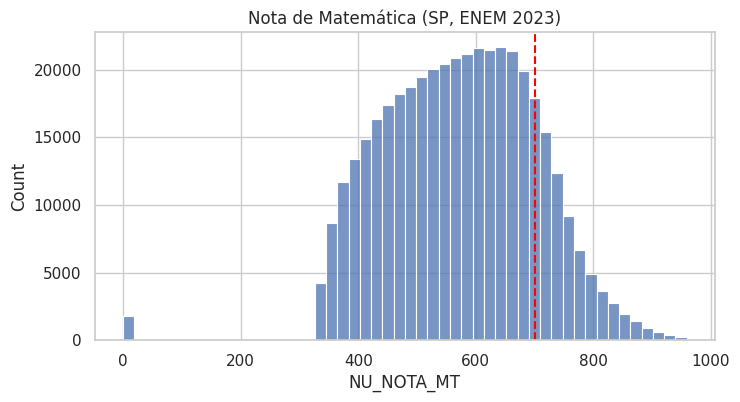

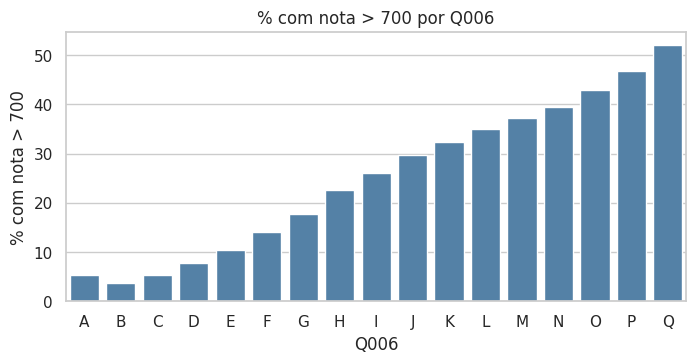

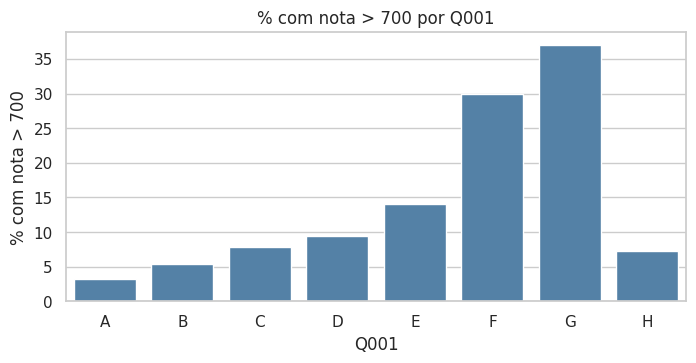

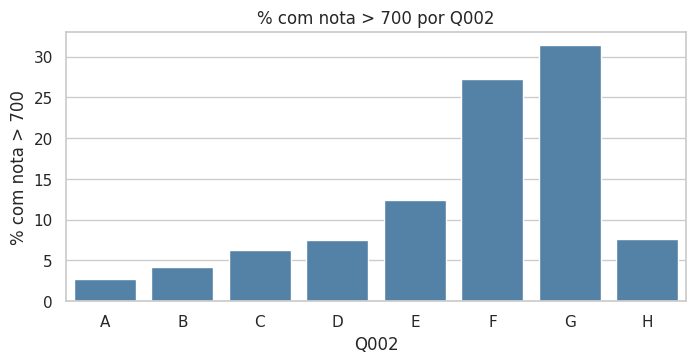

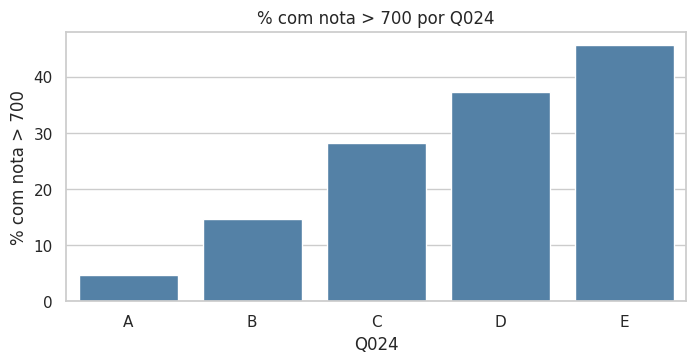

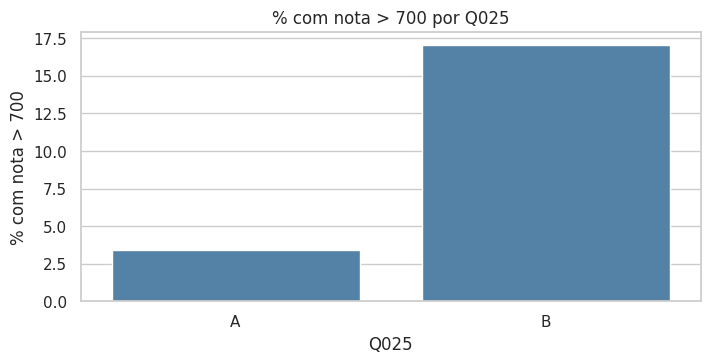

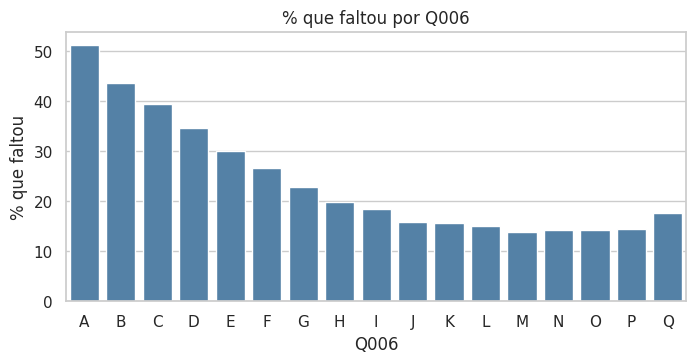

In [ ]:
# 1) Distribuição da nota
plt.figure(figsize=(8, 4))
sns.histplot(df_mt["NU_NOTA_MT"], bins=50)
plt.axvline(700, color="red", linestyle="--")
plt.title("Nota de Matemática (SP, ENEM 2023)")
plt.show()

# 2) Função para ver a taxa de um indicador por categoria
def taxa_por(coluna, base, indicador, rotulo):
    t = base.groupby(coluna)[indicador].mean().mul(100).sort_index()
    plt.figure(figsize=(8, 3.5))
    sns.barplot(x=t.index, y=t.values, color="steelblue")
    plt.ylabel(rotulo)
    plt.title(f"{rotulo} por {coluna}")
    plt.show()

# 3) % com nota > 700 em cada categoria
for q in ["Q006", "Q001", "Q002", "Q024", "Q025"]:
    taxa_por(q, df_mt, "alvo", "% com nota > 700")

# 4) % que faltou, por categoria (bom gancho para o storytelling)
df["faltou"] = (df["TP_PRESENCA_MT"] == 0).astype(int)
taxa_por("Q006", df, "faltou", "% que faltou")

In [ ]:
# Quem são os zeros?
zeros = df_mt[df_mt["NU_NOTA_MT"] == 0]
print(zeros[["TP_ST_CONCLUSAO", "IN_TREINEIRO", "TP_ESCOLA"]].apply(
    lambda s: s.value_counts(normalize=True).round(3).to_dict()))

# Treineiros x não treineiros (sem os zeros)
base = df_mt[df_mt["NU_NOTA_MT"] > 0]
print(base.groupby("IN_TREINEIRO").agg(
    n=("alvo", "size"),
    pct_alvo=("alvo", "mean"),
    nota_media=("NU_NOTA_MT", "mean")).round(3))

# Treineiros por situação de conclusão e faixa etária
print(pd.crosstab(base["IN_TREINEIRO"], base["TP_ST_CONCLUSAO"]))
print(pd.crosstab(base["IN_TREINEIRO"], base["TP_FAIXA_ETARIA"]))

TP_ST_CONCLUSAO    {2: 0.386, 1: 0.303, 3: 0.303, 4: 0.008}
IN_TREINEIRO                           {0: 0.697, 1: 0.303}
TP_ESCOLA                    {1: 0.614, 2: 0.338, 3: 0.047}
dtype: object
                   n  pct_alvo  nota_media
IN_TREINEIRO                              
0             327900     0.166     570.728
1              82148     0.178     590.843
TP_ST_CONCLUSAO       1       2      3    4
IN_TREINEIRO                               
0                138363  188677      0  860
1                     0       0  82148    0
TP_FAIXA_ETARIA     1      2       3      4      5      6     7     8     9   \
IN_TREINEIRO                                                                   
0                 1203  79341  124475  39323  19485  11635  8147  6376  4991   
1                43755  36923    1262    111      8      3     4     4     2   

TP_FAIXA_ETARIA    10     11    12    13    14    15    16   17   18   19  20  
IN_TREINEIRO                                             

#preparação dos dados

In [ ]:
# 1) Base final: presentes, sem nota zero, sem treineiros
base = df_mt[(df_mt["NU_NOTA_MT"] > 0) & (df_mt["IN_TREINEIRO"] == 0)].copy()
print(base.shape, "| proporção do alvo:", base["alvo"].mean().round(3))

# 2) Definição dos grupos de colunas
contagens = ["Q007","Q008","Q009","Q010","Q011","Q012","Q013","Q014","Q015",
             "Q016","Q017","Q019","Q022","Q024"]       # A=0, B=1, C=2...
binarias  = ["Q018","Q020","Q021","Q023","Q025"]       # A=0 (não), B=1 (sim)
nominais  = ["Q001","Q002","Q003","Q004"]              # one-hot (inclui "Não sei")

letra_para_num = lambda s: s.map(lambda x: ord(x) - ord("A"))

# 3) Matriz de atributos (apenas contexto socioeconômico)
X = pd.DataFrame(index=base.index)
X["Q005"] = base["Q005"]                      # nº de moradores
X["Q006"] = letra_para_num(base["Q006"])      # renda familiar, ordinal 0-16
for q in contagens + binarias:
    X[q] = letra_para_num(base[q])
X = pd.concat([X, pd.get_dummies(base[nominais], prefix=nominais, dtype=int)], axis=1)
y = base["alvo"]

print(X.shape, "| faltantes:", X.isna().sum().sum())

# 4) Divisão treino/teste estratificada
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(y_train.mean().round(3), y_test.mean().round(3))

(327900, 36) | proporção do alvo: 0.166
(327900, 49) | faltantes: 0
0.166 0.166


#correlação de Spearman

Q005   -0.01
Q011    0.02
Q025    0.11
Q023    0.12
Q015    0.12
Q020    0.12
Q012    0.14
Q014    0.15
Q021    0.16
Q016    0.17
Q017    0.18
Q022    0.19
Q007    0.20
Q013    0.21
Q019    0.24
Q009    0.25
Q018    0.27
Q010    0.28
Q008    0.33
Q024    0.38
Q006    0.44
Name: NU_NOTA_MT, dtype: float64


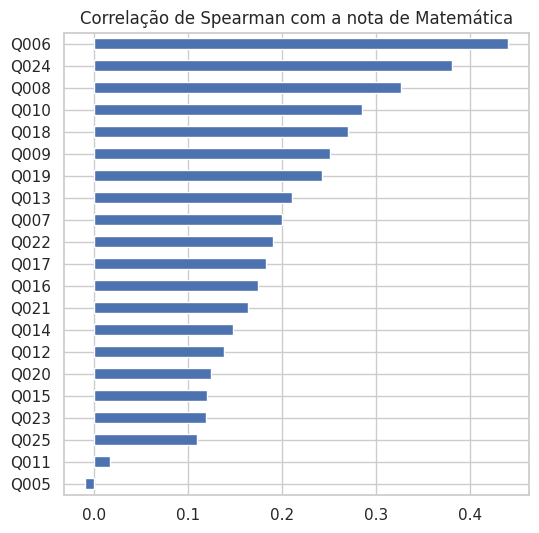

Q001 0.35
Q002 0.34


In [ ]:
cols_ord = ["Q005", "Q006"] + contagens + binarias
corr = (X[cols_ord].join(base["NU_NOTA_MT"])
        .corr(method="spearman")["NU_NOTA_MT"]
        .drop("NU_NOTA_MT").sort_values())
print(corr.round(2))

corr.plot.barh(figsize=(6, 6), title="Correlação de Spearman com a nota de Matemática")
plt.show()

# Escolaridade dos pais (sem a resposta "Não sei", que não é uma categoria ordenada)
for q in ["Q001", "Q002"]:
    sub = base[base[q] != "H"]
    r = letra_para_num(sub[q]).corr(sub["NU_NOTA_MT"], method="spearman")
    print(q, round(r, 2))

#Regressão linear (prever a nota)

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

y_nota = base["NU_NOTA_MT"]
Xtr, Xte, ytr, yte = train_test_split(X, y_nota, test_size=0.2, random_state=42)

reg = LinearRegression().fit(Xtr, ytr)
pred = reg.predict(Xte)

# Referência: "chutar" sempre a média da nota
chute = np.full(len(yte), ytr.mean())

print("R²:", round(r2_score(yte, pred), 3))
print("MAE do modelo:", round(mean_absolute_error(yte, pred), 1))
print("MAE chutando a média:", round(mean_absolute_error(yte, chute), 1))
print("RMSE:", round(np.sqrt(mean_squared_error(yte, pred)), 1))

# Quanto vale cada passo nas variáveis em escala (pontos de nota por degrau)
print(pd.Series(reg.coef_, index=X.columns)[["Q006", "Q024", "Q025"]].round(1))

R²: 0.271
MAE do modelo: 88.0
MAE chutando a média: 105.2
RMSE: 107.7
Q006     8.0
Q024    15.9
Q025     9.3
dtype: float64


#KNN (classificar nota > 700)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

# 1) Amostra de 50.000 candidatos (mantendo a proporção do alvo)
amostra = base.sample(50_000, random_state=42)
Xa, ya = X.loc[amostra.index], y.loc[amostra.index]

# 2) Separa treino e teste
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
    Xa, ya, test_size=0.2, stratify=ya, random_state=42)

# 3) Min-Max ajustado só no treino
scaler = MinMaxScaler().fit(Xa_tr)
Xtr_s, Xte_s = scaler.transform(Xa_tr), scaler.transform(Xa_te)

# 4) Escolhe k numa parte de validação (retirada do treino)
Xt, Xv, yt, yv = train_test_split(Xtr_s, ya_tr, test_size=0.25,
                                  stratify=ya_tr, random_state=42)
for k in [5, 11, 21, 41, 81]:
    m = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(Xt, yt)
    print("k =", k, "| F1 (nota > 700):", round(f1_score(yv, m.predict(Xv)), 3))

k = 5 | F1 (nota > 700): 0.313
k = 11 | F1 (nota > 700): 0.308
k = 21 | F1 (nota > 700): 0.293
k = 41 | F1 (nota > 700): 0.284
k = 81 | F1 (nota > 700): 0.279


Acurácia se chutasse sempre 'nota ≤ 700': 0.834
              precision    recall  f1-score   support

  Nota ≤ 700       0.86      0.94      0.90      8335
  Nota > 700       0.44      0.23      0.30      1665

    accuracy                           0.82     10000
   macro avg       0.65      0.59      0.60     10000
weighted avg       0.79      0.82      0.80     10000



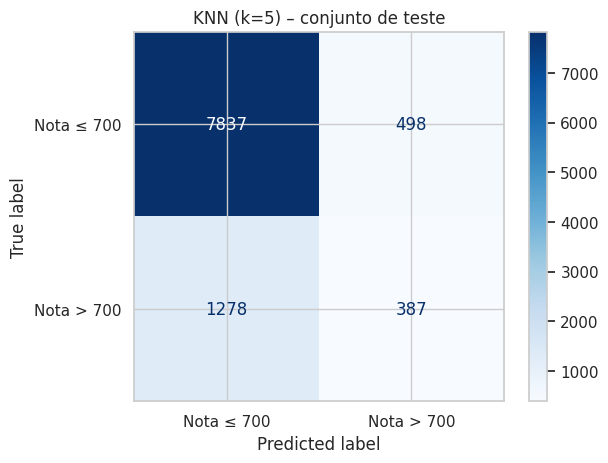

In [ ]:
k_final = 5
knn = KNeighborsClassifier(n_neighbors=k_final, n_jobs=-1).fit(Xtr_s, ya_tr)
pred = knn.predict(Xte_s)

print("Acurácia se chutasse sempre 'nota ≤ 700':", round(1 - ya_te.mean(), 3))
print(classification_report(ya_te, pred, target_names=["Nota ≤ 700", "Nota > 700"]))

ConfusionMatrixDisplay.from_predictions(
    ya_te, pred, display_labels=["Nota ≤ 700", "Nota > 700"], cmap="Blues")
plt.title(f"KNN (k={k_final}) – conjunto de teste")
plt.show()

#Preparando testes para o PoweBI

In [ ]:
# Base: candidatos não treineiros, que compareceram ou faltaram
d = df[(df["IN_TREINEIRO"] == 0) & (df["TP_PRESENCA_MT"].isin([0, 1]))].copy()
d["faltou"] = (d["TP_PRESENCA_MT"] == 0).astype(int)
d["nota"] = d["NU_NOTA_MT"].where(d["NU_NOTA_MT"] > 0)       # zeros viram vazio
d["alto"] = np.where(d["nota"].isna(), np.nan, (d["nota"] > 700).astype(float))

def resumo(col):
    return (d.groupby(col).agg(
        candidatos=("faltou", "size"),
        pct_faltou=("faltou", "mean"),
        nota_media=("nota", "mean"),
        pct_acima_700=("alto", "mean")).reset_index())

escolaridade = {"A": "Nunca estudou", "B": "Fund. incompleto (até 5º ano)",
    "C": "Fund. incompleto (até 9º ano)", "D": "Fund. completo",
    "E": "Médio completo", "F": "Superior completo",
    "G": "Pós-graduação", "H": "Não sei"}

rotulos = {
    "Q006": {"A": "Nenhuma renda", "B": "Até R$ 1.320", "C": "R$ 1.320 a 1.980",
        "D": "R$ 1.980 a 2.640", "E": "R$ 2.640 a 3.300", "F": "R$ 3.300 a 3.960",
        "G": "R$ 3.960 a 5.280", "H": "R$ 5.280 a 6.600", "I": "R$ 6.600 a 7.920",
        "J": "R$ 7.920 a 9.240", "K": "R$ 9.240 a 10.560", "L": "R$ 10.560 a 11.880",
        "M": "R$ 11.880 a 13.200", "N": "R$ 13.200 a 15.840", "O": "R$ 15.840 a 19.800",
        "P": "R$ 19.800 a 26.400", "Q": "Acima de R$ 26.400"},
    "Q001": escolaridade,
    "Q002": escolaridade,
    "Q024": {"A": "Nenhum", "B": "1", "C": "2", "D": "3", "E": "4 ou mais"},
}

tabelas = []
for q, mapa in rotulos.items():
    t = resumo(q).rename(columns={q: "codigo"})
    t.insert(0, "variavel", q)
    t["rotulo"] = t["codigo"].map(mapa)
    tabelas.append(t)

powerbi = pd.concat(tabelas, ignore_index=True)
print(powerbi.head(20))

powerbi.to_csv("powerbi_resumo_enem_sp.csv", index=False, sep=";",
               decimal=",", encoding="utf-8-sig")
from google.colab import files
files.download("powerbi_resumo_enem_sp.csv")

   variavel codigo  candidatos  pct_faltou  nota_media  pct_acima_700  \
0      Q006      A       13748    0.529168  493.752588       0.051764   
1      Q006      B       78495    0.450041  498.454797       0.036104   
2      Q006      C       86473    0.409446  522.748747       0.054063   
3      Q006      D       71831    0.367084  540.154934       0.077928   
4      Q006      E       54824    0.323927  557.886585       0.106343   
5      Q006      F       32650    0.290750  577.434809       0.147839   
6      Q006      G       49927    0.254251  593.819975       0.188490   
7      Q006      H       25426    0.220050  614.626696       0.247888   
8      Q006      I       15492    0.208172  626.711594       0.287278   
9      Q006      J       13268    0.178098  641.817299       0.332935   
10     Q006      K       10144    0.171234  651.532555       0.364525   
11     Q006      L        6420    0.157165  660.906387       0.399482   
12     Q006      M        5462    0.151959  667.154

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

for q, nome in [("Q006", "renda"), ("Q001", "pai"), ("Q002", "mae"), ("Q024", "computador")]:
    t = powerbi[powerbi["variavel"] == q].copy()
    t["ordem"] = range(len(t))          # guarda a ordem das categorias (A, B, C...)
    t.drop(columns="variavel").to_csv(f"pbi_{nome}.csv", index=False,
        sep=";", decimal=",", encoding="utf-8-sig")
    files.download(f"pbi_{nome}.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>